# Support Vector Regression (SVR)
SVR fits a function that keeps most points inside a margin of width ε around it. With an RBF kernel it can model non-linear relationships. Features and target must be scaled, because SVR relies on distances.

## Part A - Salary by position level

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
data = pd.read_csv('../data/Position_Salaries.csv')
x = data.iloc[:, 1:-1].values
y = data.iloc[:, -1].values.reshape(-1, 1)

In [3]:
from sklearn.preprocessing import StandardScaler
sc_x = StandardScaler()
sc_y = StandardScaler()
x_s = sc_x.fit_transform(x)
y_s = sc_y.fit_transform(y)

In [4]:
from sklearn.svm import SVR
svr = SVR(kernel='rbf')
svr.fit(x_s, y_s.ravel())

,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm.If none is given, 'rbf' will be used. If a callable is given it isused to precompute the kernel matrix.For an intuitive visualization of different kernel typessee :ref:`sphx_glr_auto_examples_svm_plot_svm_regression.py`",'rbf'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive.The penalty is a squared l2. For an intuitive visualization of theeffects of scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"epsilon epsilon: float, default=0.1Epsilon in the epsilon-SVR model. It specifies the epsilon-tubewithin which no penalty is associated in the training loss functionwith points predicted within a distance epsilon from the actualvalue. Must be non-negative.",0.1
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False
,"max_iter max_iter: int, default=-1Hard limit on iterations within solver, or -1 for no limit.",-1


In [5]:
sc_y.inverse_transform(svr.predict(sc_x.transform([[5.5]])).reshape(-1, 1))

array([[131106.77303274]])

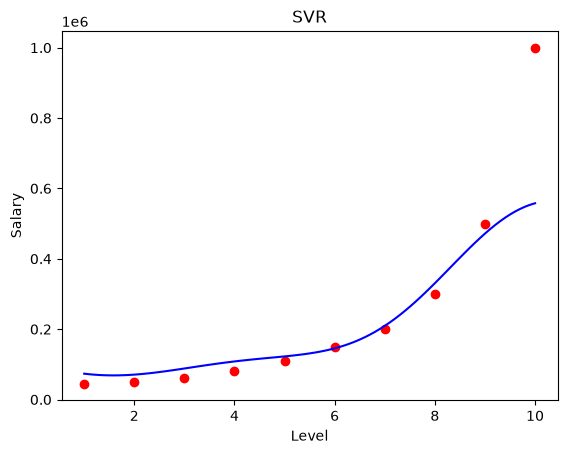

In [6]:
x_grid = np.arange(x.min(), x.max() + 0.1, 0.1).reshape(-1, 1)
plt.scatter(x, y, color='red')
plt.plot(x_grid, sc_y.inverse_transform(svr.predict(sc_x.transform(x_grid)).reshape(-1, 1)), color='blue')
plt.title('SVR')
plt.xlabel('Level')
plt.ylabel('Salary')
plt.show()

SVR treats the CEO salary (level 10) as an outlier outside the margin, so the curve stays low at the top.

## Part B - SVR on the power plant dataset
The same model on 9,568 readings with 4 features, evaluated on a held-out test set (R²).

In [7]:
dataset = pd.read_csv('../data/Power_Plant.csv')
X = dataset.iloc[:, :-1].values
Y = dataset.iloc[:, -1].values
Y = Y.reshape(-1, 1)

In [8]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, Y, test_size=0.2, random_state=0)

In [9]:
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR
sc_X = StandardScaler()
sc_Y = StandardScaler()
regressor = SVR(kernel='rbf')
regressor.fit(sc_X.fit_transform(X_train), sc_Y.fit_transform(y_train).ravel())
y_pred = sc_Y.inverse_transform(regressor.predict(sc_X.transform(X_test)).reshape(-1, 1))

In [10]:
from sklearn.metrics import r2_score, mean_squared_error
np.set_printoptions(precision=2)
print(np.concatenate((y_pred.reshape(-1, 1), np.asarray(y_test).reshape(-1, 1)), 1)[:10])
print('R2  :', round(r2_score(y_test, y_pred), 4))
print('RMSE:', round(float(np.sqrt(mean_squared_error(y_test, y_pred))), 3), 'MW')

[[434.05 431.23]
 [457.94 460.01]
 [461.03 461.14]
 [448.63 445.9 ]
 [457.83 451.29]
 [433.65 432.68]
 [473.91 477.5 ]
 [457.15 459.68]
 [474.65 477.5 ]
 [442.02 444.99]]
R2  : 0.9481
RMSE: 3.897 MW
